**Phase 1 - Data Intake & Schema Audit with Dataset Compilation**

In [ ]:
# ============================================================
# CELL 1 — Setup & Google Drive mount  (unchanged)
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np

DATA_DIR = '/content/drive/MyDrive/CS190-4P/multisource/'

Mounted at /content/drive


In [ ]:
# ============================================================
# CELL 2 — CO master timeline  (unchanged)
# ============================================================
co_raw = pd.read_csv(DATA_DIR + 'Carbon_Monoxide_Dataset.txt', sep='\t')
co_raw['Year_Month'] = co_raw['Timeline_Record'].str[:7]

master = pd.DataFrame({'Year_Month': co_raw['Year_Month']})
master['Date'] = pd.to_datetime(master['Year_Month'], format='%Y-%m')
master = master.sort_values('Date').reset_index(drop=True)

print(f"CO master timeline: {len(master)} months, "
      f"{master['Date'].min():%Y-%m} to {master['Date'].max():%Y-%m}")
assert len(master) == 296, "CO row count changed -- check the raw file"

CO master timeline: 296 months, 2000-03 to 2024-10


In [ ]:
# ============================================================
# CELL 3 — Standardized per-source loaders  (Aerosol Size added)
# ============================================================

def build(df, ym, prefix, rename_map):
    out = pd.DataFrame({'Year_Month': ym.values if hasattr(ym, 'values') else ym})
    for old, new in rename_map.items():
        out[f"{prefix}_{new}"] = df[old].values
    return out

pieces = {}

# --- CO itself ---
pieces['CO'] = build(co_raw, co_raw['Year_Month'], 'CO', {
    'Red_Pixel_Count':'Red_Pixel_Count', 'Red_Concentration_Pct':'Red_Concentration_Pct',
    'Blue_Pixel_Count':'Blue_Pixel_Count', 'Blue_Concentration_Pct':'Blue_Concentration_Pct',
    'Yellow_Pixel_Count':'Yellow_Pixel_Count', 'Yellow_Concentration_Pct':'Yellow_Concentration_Pct',
    'Purple_Pixel_Count':'Purple_Pixel_Count', 'Purple_Concentration_Pct':'Purple_Concentration_Pct',
    'Orange_Pixel_Count':'Orange_Pixel_Count', 'Orange_Concentration_Pct':'Orange_Concentration_Pct',
    'Green_Pixel_Count':'Green_Pixel_Count', 'Green_Concentration_Pct':'Green_Concentration_Pct',
})

# --- Aerosol Optical Depth (bucket classes, % only) ---
aod = pd.read_csv(DATA_DIR + 'Aerosol_Optical_Depth_Dataset.txt', sep='\t')
pieces['AOD'] = build(aod, aod['year_month_label'], 'AOD', {
    'low_concentration':'Low_Concentration_Pct',
    'medium-low_concentration':'MedLow_Concentration_Pct',
    'medium-high_concentration':'MedHigh_Concentration_Pct',
    'high_concentration':'High_Concentration_Pct',
})

# --- Aerosol Size (NEW: corrected file with real dates, 7 classes) ---
az = pd.read_csv(DATA_DIR + 'Aerosol_Size_Dataset.txt', sep='\t')
pieces['AZ'] = build(az, az['date'], 'AZ', {
    'red_pixels':'Red_Pixel_Count', 'red_concentration':'Red_Concentration_Pct',
    'blue_pixels':'Blue_Pixel_Count', 'blue_concentration':'Blue_Concentration_Pct',
    'yellow_pixels':'Yellow_Pixel_Count', 'yellow_concentration':'Yellow_Concentration_Pct',
    'white_pixels':'White_Pixel_Count', 'white_concentration':'White_Concentration_Pct',
    'purple_pixels':'Purple_Pixel_Count', 'purple_concentration':'Purple_Concentration_Pct',
    'orange_pixels':'Orange_Pixel_Count', 'orange_concentration':'Orange_Concentration_Pct',
    'green_pixels':'Green_Pixel_Count', 'green_concentration':'Green_Concentration_Pct',
})

# --- Chlorophyll (Blue/Green only, % only) ---
chl = pd.read_csv(DATA_DIR + 'Chlorophyll_Dataset.txt', sep='\t')
pieces['CHL'] = build(chl, chl['date'], 'CHL', {
    'blue_concentration':'Blue_Concentration_Pct',
    'green_concentration':'Green_Concentration_Pct',
})

# --- Land Surface Temperature (6 classes, same scheme as CO) ---
lst = pd.read_csv(DATA_DIR + 'Land_Surface_Temperature_Dataset.txt', sep='\t')
lst_ym = lst['Filename'].str[:7]
pieces['LST'] = build(lst, lst_ym, 'LST', {
    'Red Pixels':'Red_Pixel_Count', 'Red Concentration (%)':'Red_Concentration_Pct',
    'Blue Pixels':'Blue_Pixel_Count', 'Blue Concentration (%)':'Blue_Concentration_Pct',
    'Yellow Pixels':'Yellow_Pixel_Count', 'Yellow Concentration (%)':'Yellow_Concentration_Pct',
    'Purple Pixels':'Purple_Pixel_Count', 'Purple Concentration (%)':'Purple_Concentration_Pct',
    'Orange Pixels':'Orange_Pixel_Count', 'Orange Concentration (%)':'Orange_Concentration_Pct',
    'Green Pixels':'Green_Pixel_Count', 'Green Concentration (%)':'Green_Concentration_Pct',
})

# --- Net Radiation (6 classes; concentration cols unsuffixed, pixel cols _px) ---
nr = pd.read_csv(DATA_DIR + 'Net_Radiation_Dataset.txt', sep='\t')
nr_ym = nr['image'].str[:7]
pieces['NR'] = build(nr, nr_ym, 'NR', {
    'blue':'Blue_Concentration_Pct', 'blue_px':'Blue_Pixel_Count',
    'yellow':'Yellow_Concentration_Pct', 'yellow_px':'Yellow_Pixel_Count',
    'purple':'Purple_Concentration_Pct', 'purple_px':'Purple_Pixel_Count',
    'orange':'Orange_Concentration_Pct', 'orange_px':'Orange_Pixel_Count',
    'green':'Green_Concentration_Pct', 'green_px':'Green_Pixel_Count',
    'red':'Red_Concentration_Pct', 'red_px':'Red_Pixel_Count',
})

# --- Sea Surface Temperature (7 classes incl. Magenta/Cyan) ---
sst = pd.read_csv(DATA_DIR + 'Sea_Surface_Temperature_Dataset.txt', sep='\t')
pieces['SST'] = build(sst, sst['Date'], 'SST', {
    'Magenta_Pixels':'Magenta_Pixel_Count', 'Magenta_Concentration(%)':'Magenta_Concentration_Pct',
    'Blue_Pixels':'Blue_Pixel_Count', 'Blue_Concentration(%)':'Blue_Concentration_Pct',
    'Cyan_Pixels':'Cyan_Pixel_Count', 'Cyan_Concentration(%)':'Cyan_Concentration_Pct',
    'Green_Pixels':'Green_Pixel_Count', 'Green_Concentration(%)':'Green_Concentration_Pct',
    'Yellow_Pixels':'Yellow_Pixel_Count', 'Yellow_Concentration(%)':'Yellow_Concentration_Pct',
    'Orange_Pixels':'Orange_Pixel_Count', 'Orange_Concentration(%)':'Orange_Concentration_Pct',
    'Red_Pixels':'Red_Pixel_Count', 'Red_Concentration(%)':'Red_Concentration_Pct',
})

# --- Total Rainfall (7 classes incl. Gray) ---
rain = pd.read_csv(DATA_DIR + 'Total_Rainfall_Dataset.txt', sep='\t')
pieces['RAIN'] = build(rain, rain['date'], 'RAIN', {
    'red_pixels':'Red_Pixel_Count', 'red_concentration':'Red_Concentration_Pct',
    'orange_pixels':'Orange_Pixel_Count', 'orange_concentration':'Orange_Concentration_Pct',
    'yellow_pixels':'Yellow_Pixel_Count', 'yellow_concentration':'Yellow_Concentration_Pct',
    'green_pixels':'Green_Pixel_Count', 'green_concentration':'Green_Concentration_Pct',
    'blue_pixels':'Blue_Pixel_Count', 'blue_concentration':'Blue_Concentration_Pct',
    'purple_pixels':'Purple_Pixel_Count', 'purple_concentration':'Purple_Concentration_Pct',
    'gray_pixels':'Gray_Pixel_Count', 'gray_concentration':'Gray_Concentration_Pct',
})

# --- Vegetation (single class) ---
veg = pd.read_csv(DATA_DIR + 'Vegetation_Dataset.txt', sep='\t')
veg_ym = veg['year'].astype(str) + '-' + veg['month'].astype(str).str.zfill(2)
pieces['VEG'] = build(veg, veg_ym, 'VEG', {
    'vegetation_pixels':'Vegetation_Pixel_Count',
    'vegetation_concentration':'Vegetation_Concentration_Pct',
    'mean_green_intensity':'Mean_Green_Intensity',
})

# --- Water Vapor (3 classes: Blue/White/Gray) ---
wv = pd.read_csv(DATA_DIR + 'Water_Vapor_Dataset.txt', sep='\t')
wv_ym = wv['image'].str[:7]
pieces['WV'] = build(wv, wv_ym, 'WV', {
    'Blue Pixels':'Blue_Pixel_Count', 'Blue Pixels concentration':'Blue_Concentration_Pct',
    'White pixels':'White_Pixel_Count', 'white pixels concentration':'White_Concentration_Pct',
    'gray pixels':'Gray_Pixel_Count', 'gray pixels concentration':'Gray_Concentration_Pct',
})

print(f"Loaded {len(pieces)} sources: {list(pieces.keys())}")

Loaded 10 sources: ['CO', 'AOD', 'AZ', 'CHL', 'LST', 'NR', 'SST', 'RAIN', 'VEG', 'WV']


In [ ]:
# ============================================================
# CELL 4 — Merge + coverage audit  (unchanged)
# ============================================================
for name, p in pieces.items():
    before = len(master)
    master = master.merge(p, on='Year_Month', how='left')
    assert len(master) == before, f"{name} merge changed row count -- duplicate Year_Month in source!"

print("Final compiled shape:", master.shape)
print("\n--- Per-source coverage over CO's 296-month timeline ---")
for name, p in pieces.items():
    cols = [c for c in p.columns if c != 'Year_Month']
    covered = master[cols].notna().any(axis=1).sum()
    print(f"  {name:6s}: {covered:3d}/296 months ({covered/296*100:5.1f}%)  | {len(cols)} columns")

Final compiled shape: (296, 95)

--- Per-source coverage over CO's 296-month timeline ---
  CO    : 296/296 months (100.0%)  | 12 columns
  AOD   : 296/296 months (100.0%)  | 4 columns
  AZ    : 141/296 months ( 47.6%)  | 14 columns
  CHL   : 265/296 months ( 89.5%)  | 2 columns
  LST   : 296/296 months (100.0%)  | 12 columns
  NR    : 220/296 months ( 74.3%)  | 12 columns
  SST   : 268/296 months ( 90.5%)  | 14 columns
  RAIN  : 296/296 months (100.0%)  | 14 columns
  VEG   : 118/296 months ( 39.9%)  | 3 columns
  WV    : 296/296 months (100.0%)  | 6 columns


In [ ]:
# ============================================================
# CELL 5 — Export to Excel  (audit table updated with AZ)
# ============================================================
audit_rows = [
    ('CO', '2000-03', '2024-10', 296, 100.0, 'Label source / master timeline. 6 classes.'),
    ('AOD', '2000-03', '2025-12', 296, 100.0, '4 bucket classes, % only, no pixel counts.'),
    ('AZ', '2005-01', '2016-09', 141, 47.6, 'Confirmed monthly, no internal gaps. 7 classes incl. White. No coverage before 2005 or after 2016.'),
    ('CHL', '2002-07', '2026-02', 265, 89.5, 'Blue/Green only. Gaps: 2020-05, 2020-06, 2022-05.'),
    ('LST', '2000-02', '2026-04', 296, 100.0, '6 classes, same scheme as CO.'),
    ('NR', '2006-07', '2026-04', 220, 74.3, 'No coverage before 2006-07.'),
    ('SST', '2002-07', '2026-03', 268, 90.5, '7 classes incl. Magenta/Cyan.'),
    ('RAIN', '1998-01', '2026-04', 296, 100.0, '7 classes incl. Gray.'),
    ('VEG', '2000-02', '2009-12', 118, 39.9, 'SEVERE gap: no coverage after 2009-12. Single class.'),
    ('WV', '2000-02', '2026-04', 296, 100.0, '3 classes: Blue/White/Gray.'),
]
audit_df = pd.DataFrame(audit_rows, columns=[
    'Source', 'Range_Start', 'Range_End', 'Months_Covered', 'Coverage_Pct', 'Notes'
])

output_path = DATA_DIR + 'CO_Multisource_Compiled.xlsx'
with pd.ExcelWriter(output_path, engine='openpyxl') as writer:
    master.to_excel(writer, sheet_name='Master_Compiled', index=False)
    audit_df.to_excel(writer, sheet_name='Schema_Audit', index=False)

print(f"Saved: {output_path}")
print(f"Shape: {master.shape[0]} rows x {master.shape[1]} columns")

from google.colab import files
files.download(output_path)

Saved: /content/drive/MyDrive/CS190-4P/multisource/CO_Multisource_Compiled.xlsx
Shape: 296 rows x 95 columns


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Phase 2 - Pre-processing & Transformation**

In [ ]:
# ============================================================
# CELL 1 — Load Phase 1 output
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np

DATA_DIR = '/content/drive/MyDrive/CS190-4P/multisource/'
master = pd.read_excel(DATA_DIR + 'CO_Multisource_Compiled.xlsx', sheet_name='Master_Compiled')
master['Date'] = pd.to_datetime(master['Date'])
print("Loaded:", master.shape)

Mounted at /content/drive
Loaded: (296, 95)


In [ ]:
# ============================================================
# CELL 2 — Hard constraint check: test-period coverage
# A feature that doesn't exist during the evaluation window
# cannot be used as a real-time input, no matter how much
# historical data it has. This is not a threshold judgment --
# it's a structural requirement for a forecasting model.
# ============================================================
split_idx = int(len(master) * 0.80)
test_start, test_end = master['Date'].iloc[split_idx], master['Date'].iloc[-1]
print(f"Test period: {test_start:%Y-%m} to {test_end:%Y-%m} ({len(master)-split_idx} months)\n")

pct_cols = [c for c in master.columns if c.endswith('_Concentration_Pct')]
sources = sorted(set(c.split('_')[0] for c in pct_cols) - {'CO'})

usable, excluded = [], []
for src in sources:
    cols = [c for c in pct_cols if c.startswith(src+'_')]
    test_missing = master.loc[split_idx:, cols].isna().all(axis=1).sum()
    coverage = 1 - test_missing/(len(master)-split_idx)
    print(f"{src:5s}: {coverage*100:5.1f}% test-period coverage -> "
          f"{'USABLE' if coverage > 0.9 else 'STRUCTURALLY EXCLUDED'}")
    (usable if coverage > 0.9 else excluded).append(src)

print(f"\nUsable sources: {usable}")
print(f"Excluded (no test-period data): {excluded}")
print("Note: AZ and VEG are expected here -- AZ ends 2016-09, VEG ends 2009-12,")
print("both fully before the test window starts. This is structural, not a soft call.")

Test period: 2019-11 to 2024-10 (60 months)

AOD  : 100.0% test-period coverage -> USABLE
AZ   :   0.0% test-period coverage -> STRUCTURALLY EXCLUDED
CHL  :  95.0% test-period coverage -> USABLE
LST  : 100.0% test-period coverage -> USABLE
NR   : 100.0% test-period coverage -> USABLE
RAIN : 100.0% test-period coverage -> USABLE
SST  : 100.0% test-period coverage -> USABLE
VEG  :   0.0% test-period coverage -> STRUCTURALLY EXCLUDED
WV   : 100.0% test-period coverage -> USABLE

Usable sources: ['AOD', 'CHL', 'LST', 'NR', 'RAIN', 'SST', 'WV']
Excluded (no test-period data): ['AZ', 'VEG']
Note: AZ and VEG are expected here -- AZ ends 2016-09, VEG ends 2009-12,
both fully before the test window starts. This is structural, not a soft call.


In [ ]:
# ============================================================
# CELL 3 — Variance/mean screen: drop near-zero-signal classes
# Same logic we applied to CO's own Blue/Purple/Green. A class
# with mean < 1% AND std < 1% carries essentially no learnable
# signal and just adds noise + dimensionality.
# ============================================================
usable_sources = usable  # from Cell 2

keep_feats, drop_feats = [], []
for c in pct_cols:
    src = c.split('_')[0]
    if src == 'CO' or src not in usable_sources:
        continue
    m, s = master[c].mean(skipna=True), master[c].std(skipna=True)
    if m < 1.0 and s < 1.0:
        drop_feats.append(c)
    else:
        keep_feats.append(c)

print(f"Kept: {len(keep_feats)} | Dropped as near-zero signal: {len(drop_feats)}")
print("\nDropped:", drop_feats)

Kept: 19 | Dropped as near-zero signal: 16

Dropped: ['AOD_High_Concentration_Pct', 'LST_Yellow_Concentration_Pct', 'LST_Orange_Concentration_Pct', 'LST_Green_Concentration_Pct', 'NR_Yellow_Concentration_Pct', 'NR_Green_Concentration_Pct', 'NR_Red_Concentration_Pct', 'SST_Cyan_Concentration_Pct', 'SST_Green_Concentration_Pct', 'SST_Yellow_Concentration_Pct', 'SST_Orange_Concentration_Pct', 'RAIN_Red_Concentration_Pct', 'RAIN_Orange_Concentration_Pct', 'RAIN_Yellow_Concentration_Pct', 'RAIN_Purple_Concentration_Pct', 'RAIN_Gray_Concentration_Pct']


In [ ]:
# ============================================================
# CELL 4 — Correlation + Mutual Information ranking vs CO targets
# Correlation catches linear relationships; MI catches nonlinear
# ones too (a GRU can exploit both). We use both so we're not
# blind to a feature that's nonlinearly useful but linearly quiet.
# ============================================================
from sklearn.feature_selection import mutual_info_regression

co_targets = ['CO_Red_Concentration_Pct','CO_Yellow_Concentration_Pct','CO_Orange_Concentration_Pct']

corr_rows = []
for c in keep_feats:
    row = {'feature': c}
    for t in co_targets:
        valid = master[[c, t]].dropna()
        row[t.split('_')[1]] = valid[c].corr(valid[t]) if len(valid) > 10 else np.nan
    corr_rows.append(row)
corr_df = pd.DataFrame(corr_rows).set_index('feature')
corr_df['max_abs_corr'] = corr_df.abs().max(axis=1)

mi_results = {}
for t in co_targets:
    valid = master[keep_feats + [t]].dropna()
    mi = mutual_info_regression(valid[keep_feats], valid[t], random_state=42)
    mi_results[t.split('_')[1]] = pd.Series(mi, index=keep_feats)
mi_df = pd.DataFrame(mi_results)
mi_df['max_mi'] = mi_df.max(axis=1)

ranking = corr_df[['max_abs_corr']].join(mi_df[['max_mi']]).sort_values('max_mi', ascending=False)
print("=== Feature ranking (correlation + mutual information) ===")
print(ranking.round(3))

=== Feature ranking (correlation + mutual information) ===
                               max_abs_corr  max_mi
feature                                            
LST_Blue_Concentration_Pct            0.165   0.698
NR_Orange_Concentration_Pct           0.099   0.528
NR_Purple_Concentration_Pct           0.581   0.480
NR_Blue_Concentration_Pct             0.569   0.344
WV_Gray_Concentration_Pct             0.230   0.267
LST_Purple_Concentration_Pct          0.174   0.261
LST_Red_Concentration_Pct             0.172   0.248
WV_White_Concentration_Pct            0.267   0.242
SST_Magenta_Concentration_Pct         0.207   0.201
WV_Blue_Concentration_Pct             0.229   0.193
AOD_MedLow_Concentration_Pct          0.082   0.183
RAIN_Blue_Concentration_Pct           0.222   0.182
CHL_Green_Concentration_Pct           0.311   0.176
AOD_MedHigh_Concentration_Pct         0.073   0.169
RAIN_Green_Concentration_Pct          0.122   0.165
CHL_Blue_Concentration_Pct            0.313   0.159
SST_R

In [ ]:
# ============================================================
# CELL 5 — Interpolate small bounded gaps, add cyclical features
# CHL has 3 scattered single/double-month gaps INSIDE the valid
# range -- small and bounded on both sides, safe to interpolate.
# The large LEADING gaps in CHL/SST/NR are NOT imputed here --
# they become natural tier boundaries in Cell 6 instead.
# ============================================================
chl_cols = [c for c in keep_feats if c.startswith('CHL_')]
master[chl_cols] = master[chl_cols].interpolate(method='linear', limit_area='inside')

master['month_sin'] = np.sin(2*np.pi*master['Date'].dt.month/12)
master['month_cos'] = np.cos(2*np.pi*master['Date'].dt.month/12)

print("Remaining NaNs in kept features after targeted interpolation:")
print(master[keep_feats].isna().sum()[master[keep_feats].isna().sum() > 0])

Remaining NaNs in kept features after targeted interpolation:
CHL_Blue_Concentration_Pct       28
CHL_Green_Concentration_Pct      28
NR_Blue_Concentration_Pct        76
NR_Purple_Concentration_Pct      76
NR_Orange_Concentration_Pct      76
SST_Magenta_Concentration_Pct    28
SST_Blue_Concentration_Pct       28
SST_Red_Concentration_Pct        28
dtype: int64


In [ ]:
# ============================================================
# CELL 6 — Build 3 tiered, fully-complete candidate datasets
# Each tier trades training-data volume against feature richness.
# Phase 3 tests all three empirically rather than us guessing here.
# ============================================================
tier1_feats = [c for c in keep_feats if c.split('_')[0] in ('AOD','LST','RAIN','WV')]
tier2_feats = tier1_feats + [c for c in keep_feats if c.split('_')[0] in ('CHL','SST')]
tier3_feats = tier2_feats + [c for c in keep_feats if c.split('_')[0] == 'NR']

aux_cols = ['Year_Month','Date','month_sin','month_cos'] + co_targets

tier1_df = master[aux_cols + tier1_feats].copy()
tier2_df = master.loc[master[tier2_feats].notna().all(axis=1), aux_cols + tier2_feats].reset_index(drop=True)
tier3_df = master.loc[master[tier3_feats].notna().all(axis=1), aux_cols + tier3_feats].reset_index(drop=True)

for name, df in [('Tier1 (full history)', tier1_df), ('Tier2 (+ocean/chlorophyll)', tier2_df), ('Tier3 (+net radiation)', tier3_df)]:
    assert df.isna().sum().sum() == 0, f"{name} still has NaNs -- stop and check"
    n_feat = df.shape[1] - len(aux_cols)
    print(f"{name}: {df.shape[0]} months, {n_feat} exogenous features, "
          f"{df['Date'].min():%Y-%m}–{df['Date'].max():%Y-%m}, "
          f"{df.shape[0]-12} windows at 12-month lookback")

Tier1 (full history): 296 months, 11 exogenous features, 2000-03–2024-10, 284 windows at 12-month lookback
Tier2 (+ocean/chlorophyll): 268 months, 16 exogenous features, 2002-07–2024-10, 256 windows at 12-month lookback
Tier3 (+net radiation): 220 months, 19 exogenous features, 2006-07–2024-10, 208 windows at 12-month lookback


In [ ]:
# ============================================================
# CELL 7 — Export Phase 2 output
# ============================================================
output_path = DATA_DIR + 'CO_Phase2_Ready.xlsx'
with pd.ExcelWriter(output_path, engine='openpyxl') as writer:
    tier1_df.to_excel(writer, sheet_name='Tier1_FullHistory', index=False)
    tier2_df.to_excel(writer, sheet_name='Tier2_Ocean_Chl', index=False)
    tier3_df.to_excel(writer, sheet_name='Tier3_NetRadiation', index=False)
    ranking.to_excel(writer, sheet_name='Feature_Ranking')

print(f"Saved: {output_path}")
from google.colab import files
files.download(output_path)

Saved: /content/drive/MyDrive/CS190-4P/multisource/CO_Phase2_Ready.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Phase 3 - Model Architecture & Training**

In [ ]:
# Cell 1 — Setup

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, numpy as np, warnings
warnings.filterwarnings('ignore')
import tensorflow as tf
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Input, GRU, Dropout, Dense, Conv1D, Layer
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = '/content/drive/MyDrive/CS190-4P/multisource/'
RANDOM_SEED = 42
LOOK_BACK = 12
TARGET_COLS = ['CO_Red_Concentration_Pct','CO_Yellow_Concentration_Pct','CO_Orange_Concentration_Pct']

xl = pd.ExcelFile(DATA_DIR + 'CO_Phase2_Ready.xlsx')
tier1 = xl.parse('Tier1_FullHistory'); tier1['Date'] = pd.to_datetime(tier1['Date'])
tier2 = xl.parse('Tier2_Ocean_Chl');   tier2['Date'] = pd.to_datetime(tier2['Date'])
tier3 = xl.parse('Tier3_NetRadiation');tier3['Date'] = pd.to_datetime(tier3['Date'])

# Fixed test window established in Phase 1/2 -- same 60 months for every tier
full_dates = tier1['Date']
split_idx = int(len(full_dates) * 0.80)
TEST_START, TEST_END = full_dates.iloc[split_idx], full_dates.iloc[-1]
print(f"Fixed test window: {TEST_START:%Y-%m} to {TEST_END:%Y-%m}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Fixed test window: 2019-11 to 2024-10


In [ ]:
# Cell 2 — Shared windowing pipeline


def prepare_tier(df, feature_cols, test_start, test_end):
    df = df.sort_values('Date').reset_index(drop=True)
    train_df = df[df['Date'] < test_start].reset_index(drop=True)
    test_df = df[(df['Date'] >= test_start) & (df['Date'] <= test_end)].reset_index(drop=True)

    scaler = MinMaxScaler((0,1))
    train_t = scaler.fit_transform(train_df[TARGET_COLS])
    test_t = scaler.transform(test_df[TARGET_COLS])

    exog_scaler = MinMaxScaler((0,1))
    train_x = exog_scaler.fit_transform(train_df[feature_cols]) if feature_cols else np.empty((len(train_df),0))
    test_x = exog_scaler.transform(test_df[feature_cols]) if feature_cols else np.empty((len(test_df),0))

    train_feat = np.hstack([train_t, train_x, train_df[['month_sin','month_cos']].values])
    test_feat = np.hstack([test_t, test_x, test_df[['month_sin','month_cos']].values])
    full_feat = np.vstack([train_feat, test_feat])
    full_target = np.vstack([train_t, test_t])
    full_dates_ = pd.concat([train_df['Date'], test_df['Date']]).reset_index(drop=True)

    X, y, dts = [], [], []
    for i in range(len(full_feat) - LOOK_BACK):
        X.append(full_feat[i:i+LOOK_BACK]); y.append(full_target[i+LOOK_BACK]); dts.append(full_dates_[i+LOOK_BACK])
    X, y, dts = np.array(X), np.array(y), np.array(dts)
    n_train_w = len(train_feat) - LOOK_BACK

    return {'X_train':X[:n_train_w], 'y_train':y[:n_train_w], 'X_test':X[n_train_w:], 'y_test':y[n_train_w:],
            'dates_test':dts[n_train_w:], 'scaler':scaler}

def inv(scaler, y): return scaler.inverse_transform(y)

def evaluate(y_true, y_pred):
    out = {}
    for i,c in enumerate(['Red','Yellow','Orange']):
        out[c] = {'MAE':mean_absolute_error(y_true[:,i],y_pred[:,i]),
                   'RMSE':np.sqrt(mean_squared_error(y_true[:,i],y_pred[:,i])),
                   'R2':r2_score(y_true[:,i],y_pred[:,i])}
    return out

In [ ]:
# Cell 3 — Candidate architectures

def build_plain_gru(n_t, n_f, units=24):
    tf.random.set_seed(RANDOM_SEED)
    m = Sequential([Input(shape=(n_t,n_f)), GRU(units, kernel_regularizer=l2(1e-4)),
                     Dropout(0.3), Dense(16,activation='relu',kernel_regularizer=l2(1e-4)),
                     Dense(3, activation='linear')])
    m.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss=tf.keras.losses.Huber(delta=0.1), metrics=['mae'])
    return m

def build_conv_gru(n_t, n_f, conv_filters=12, gru_units=20):
    """Conv1D compresses the wide multivariate input before the GRU sees it --
    controls the feature-to-sample ratio that grows with each tier."""
    tf.random.set_seed(RANDOM_SEED)
    inp = Input(shape=(n_t,n_f))
    x = Conv1D(conv_filters, kernel_size=3, padding='causal', activation='relu', kernel_regularizer=l2(1e-4))(inp)
    x = GRU(gru_units, kernel_regularizer=l2(1e-4))(x)
    x = Dropout(0.3)(x)
    x = Dense(16, activation='relu', kernel_regularizer=l2(1e-4))(x)
    out = Dense(3, activation='linear')(x)
    m = Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss=tf.keras.losses.Huber(delta=0.1), metrics=['mae'])
    return m

def get_callbacks():
    return [EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True),
            ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-5)]

In [ ]:
# Cell 4 — Architecture ablation on Tier 1 (justify the Conv1D+GRU choice with evidence)

feat_cols_t1 = [c for c in tier1.columns if c not in ['Year_Month','Date','month_sin','month_cos']+TARGET_COLS]
d1 = prepare_tier(tier1, feat_cols_t1, TEST_START, TEST_END)
X_train, y_train = d1['X_train'], d1['y_train']
n_val = int(len(X_train)*0.15)
X_tr,y_tr = X_train[:-n_val], y_train[:-n_val]
X_val,y_val = X_train[-n_val:], y_train[-n_val:]
last_tr, last_val, last_test = X_tr[:,-1,:3], X_val[:,-1,:3], d1['X_test'][:,-1,:3]
y_tr_d, y_val_d = y_tr-last_tr, y_val-last_val
y_test_real = inv(d1['scaler'], d1['y_test'])

print("=== Architecture ablation (Tier 1) ===")
for name, builder in [('Plain GRU', build_plain_gru), ('Conv1D+GRU', build_conv_gru)]:
    model = builder(X_train.shape[1], X_train.shape[2])
    model.fit(X_tr, y_tr_d, validation_data=(X_val,y_val_d), epochs=200, batch_size=8, callbacks=get_callbacks(), verbose=0)
    pred = inv(d1['scaler'], last_test + model.predict(d1['X_test'], verbose=0))
    m = evaluate(y_test_real, pred)
    print(f"{name}: Red R2={m['Red']['R2']:.3f}  Yellow R2={m['Yellow']['R2']:.3f}  Orange R2={m['Orange']['R2']:.3f}")

=== Architecture ablation (Tier 1) ===
Plain GRU: Red R2=0.575  Yellow R2=0.346  Orange R2=-1.070
Conv1D+GRU: Red R2=0.599  Yellow R2=0.374  Orange R2=-1.114


In [ ]:
# Cell 5 — Baselines (persistence, seasonal-naive, linear regression per tier)

persistence_pred = inv(d1['scaler'], d1['X_test'][:,-1,:3])
seasonal_pred = inv(d1['scaler'], d1['X_test'][:,0,:3])
print("Persistence:", {k:round(v['R2'],3) for k,v in evaluate(y_test_real, persistence_pred).items()})
print("Seasonal-naive:", {k:round(v['R2'],3) for k,v in evaluate(y_test_real, seasonal_pred).items()})

print("\nLinear Regression per tier (demonstrates WHY we need a regularized architecture):")
for name, df in [('Tier1',tier1),('Tier2',tier2),('Tier3',tier3)]:
    fcols = [c for c in df.columns if c not in ['Year_Month','Date','month_sin','month_cos']+TARGET_COLS]
    d = prepare_tier(df, fcols, TEST_START, TEST_END)
    Xtr_f, Xte_f = d['X_train'].reshape(len(d['X_train']),-1), d['X_test'].reshape(len(d['X_test']),-1)
    yte_real = inv(d['scaler'], d['y_test'])
    preds = np.zeros_like(d['y_test'])
    for i in range(3):
        preds[:,i] = LinearRegression().fit(Xtr_f, d['y_train'][:,i]).predict(Xte_f)
    m = evaluate(yte_real, inv(d['scaler'], preds))
    print(f"  {name}: Red={m['Red']['R2']:.2f} Yellow={m['Yellow']['R2']:.2f} Orange={m['Orange']['R2']:.2f}  <- flattened-window overfitting")

Persistence: {'Red': 0.197, 'Yellow': -0.006, 'Orange': -1.097}
Seasonal-naive: {'Red': 0.476, 'Yellow': 0.059, 'Orange': -1.303}

Linear Regression per tier (demonstrates WHY we need a regularized architecture):
  Tier1: Red=-0.71 Yellow=-5.42 Orange=-19.11  <- flattened-window overfitting
  Tier2: Red=-3.35 Yellow=-44.42 Orange=-133.50  <- flattened-window overfitting
  Tier3: Red=-0.03 Yellow=-4.65 Orange=-12.06  <- flattened-window overfitting


In [ ]:
# Cell 6 — Final tiered comparison (the core Phase 3 result)

print("=== Conv1D+GRU across all 3 tiers (same fixed test window) ===")
tier_results = {}
for name, df in [('Tier1',tier1),('Tier2',tier2),('Tier3',tier3)]:
    fcols = [c for c in df.columns if c not in ['Year_Month','Date','month_sin','month_cos']+TARGET_COLS]
    d = prepare_tier(df, fcols, TEST_START, TEST_END)
    Xtr, ytr = d['X_train'], d['y_train']
    nv = int(len(Xtr)*0.15)
    Xt,yt = Xtr[:-nv], ytr[:-nv]; Xv,yv = Xtr[-nv:], ytr[-nv:]
    lt,lv,lte = Xt[:,-1,:3], Xv[:,-1,:3], d['X_test'][:,-1,:3]
    model = build_conv_gru(Xtr.shape[1], Xtr.shape[2])
    model.fit(Xt, yt-lt, validation_data=(Xv,yv-lv), epochs=200, batch_size=8, callbacks=get_callbacks(), verbose=0)
    pred = inv(d['scaler'], lte + model.predict(d['X_test'], verbose=0))
    m = evaluate(inv(d['scaler'], d['y_test']), pred)
    tier_results[name] = m
    print(f"{name} (train_windows={len(Xtr)}, features={Xtr.shape[2]}): "
          f"Red R2={m['Red']['R2']:.3f} Yellow R2={m['Yellow']['R2']:.3f} Orange R2={m['Orange']['R2']:.3f}")

# keep Tier2's model/scaler/data as the primary result for later cells
final_model, final_data = None, None

=== Conv1D+GRU across all 3 tiers (same fixed test window) ===


Tier1 (train_windows=224, features=16): Red R2=0.499 Yellow R2=0.305 Orange R2=-1.108
Tier2 (train_windows=196, features=21): Red R2=0.534 Yellow R2=0.272 Orange R2=-1.059
Tier3 (train_windows=148, features=24): Red R2=0.734 Yellow R2=0.343 Orange R2=-1.030


In [ ]:
# Cell 7 — Walk-forward validation on the chosen Tier 2 model

d2 = prepare_tier(tier2, [c for c in tier2.columns if c not in ['Year_Month','Date','month_sin','month_cos']+TARGET_COLS], TEST_START, TEST_END)
X_train2 = d2['X_train']; y_train2 = d2['y_train']
fold_bounds = [int(len(X_train2)*f) for f in (0.6,0.75,0.9,1.0)]
print("=== Walk-forward validation: Tier2 Conv1D+GRU ===")
for i in range(len(fold_bounds)-1):
    tr_end, val_start, val_end = fold_bounds[i], fold_bounds[i], fold_bounds[i+1]
    Xtr,ytr = X_train2[:tr_end], y_train2[:tr_end]
    Xval,yval = X_train2[val_start:val_end], y_train2[val_start:val_end]
    lt, lv = Xtr[:,-1,:3], Xval[:,-1,:3]
    m = build_conv_gru(Xtr.shape[1], Xtr.shape[2])
    m.fit(Xtr, ytr-lt, epochs=150, batch_size=8, callbacks=[EarlyStopping(monitor='loss',patience=15,restore_best_weights=True)], verbose=0)
    pred_real = inv(d2['scaler'], lv + m.predict(Xval, verbose=0))
    actual_real = inv(d2['scaler'], yval)
    r2s = {c: round(r2_score(actual_real[:,j], pred_real[:,j]),3) for j,c in enumerate(['Red','Yellow','Orange'])}
    print(f"Fold {i+1} (train={tr_end}, val={val_end-val_start}): {r2s}")

=== Walk-forward validation: Tier2 Conv1D+GRU ===
Fold 1 (train=117, val=30): {'Red': 0.666, 'Yellow': 0.85, 'Orange': 0.261}
Fold 2 (train=147, val=29): {'Red': 0.603, 'Yellow': 0.798, 'Orange': 0.298}
Fold 3 (train=176, val=20): {'Red': 0.554, 'Yellow': 0.436, 'Orange': -0.694}


In [ ]:
# Cell 8 — Permutation feature importance (which exogenous sources actually helped)

feat_cols_t2 = [c for c in tier2.columns if c not in ['Year_Month','Date','month_sin','month_cos']+TARGET_COLS]
Xtr2, ytr2 = d2['X_train'], d2['y_train']
nv = int(len(Xtr2)*0.15)
Xt,yt = Xtr2[:-nv], ytr2[:-nv]; Xv,yv = Xtr2[-nv:], ytr2[-nv:]
lt,lv,lte = Xt[:,-1,:3], Xv[:,-1,:3], d2['X_test'][:,-1,:3]

final_model = build_conv_gru(Xtr2.shape[1], Xtr2.shape[2])
final_model.fit(Xt, yt-lt, validation_data=(Xv,yv-lv), epochs=200, batch_size=8, callbacks=get_callbacks(), verbose=0)

y_test_real2 = inv(d2['scaler'], d2['y_test'])
base_pred = inv(d2['scaler'], lte + final_model.predict(d2['X_test'], verbose=0))
base_r2 = r2_score(y_test_real2[:,0], base_pred[:,0])

all_feat_names = TARGET_COLS + feat_cols_t2 + ['month_sin','month_cos']
importances = []
rng = np.random.RandomState(42)
for fi, fname in enumerate(all_feat_names):
    Xp = d2['X_test'].copy()
    flat = Xp[:,:,fi].flatten(); rng.shuffle(flat); Xp[:,:,fi] = flat.reshape(Xp[:,:,fi].shape)
    pred_perm = inv(d2['scaler'], Xp[:,-1,:3] + final_model.predict(Xp, verbose=0))
    importances.append((fname, base_r2 - r2_score(y_test_real2[:,0], pred_perm[:,0])))

importances.sort(key=lambda x: -x[1])
print(f"Baseline Red R2: {base_r2:.4f}\nTop feature contributions (R2 drop when shuffled):")
for fname, drop in importances[:10]:
    print(f"  {fname:35s} {drop:+.4f}")

Baseline Red R2: 0.5842
Top feature contributions (R2 drop when shuffled):
  CO_Red_Concentration_Pct            +0.9379
  month_cos                           +0.2903
  month_sin                           +0.2309
  WV_White_Concentration_Pct          +0.0511
  WV_Blue_Concentration_Pct           +0.0225
  CHL_Blue_Concentration_Pct          +0.0191
  CO_Yellow_Concentration_Pct         +0.0146
  LST_Purple_Concentration_Pct        +0.0109
  SST_Blue_Concentration_Pct          +0.0071
  AOD_Low_Concentration_Pct           +0.0056


In [ ]:
# Cell 9 — Export final results

summary_rows = []
for tier, m in tier_results.items():
    for c in ['Red','Yellow','Orange']:
        summary_rows.append({'Tier':tier, 'Color':c, 'MAE':m[c]['MAE'], 'RMSE':m[c]['RMSE'], 'R2':m[c]['R2']})
summary_df = pd.DataFrame(summary_rows)

output_path = DATA_DIR + 'CO_Phase3_Results.xlsx'
with pd.ExcelWriter(output_path, engine='openpyxl') as writer:
    summary_df.to_excel(writer, sheet_name='Tier_Comparison', index=False)
    pd.DataFrame(importances, columns=['Feature','R2_Drop']).to_excel(writer, sheet_name='Feature_Importance', index=False)

print(f"Saved: {output_path}")
from google.colab import files
files.download(output_path)

Saved: /content/drive/MyDrive/CS190-4P/multisource/CO_Phase3_Results.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Phase 4 - Testing and Validation**

In [ ]:
# Cell 1 — Setup

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, numpy as np, warnings, pickle
warnings.filterwarnings('ignore')
import tensorflow as tf
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Input, GRU, Dropout, Dense, Conv1D
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

DATA_DIR = '/content/drive/MyDrive/CS190-4P/multisource/'
LOOK_BACK = 12
TARGET_COLS = ['CO_Red_Concentration_Pct','CO_Yellow_Concentration_Pct','CO_Orange_Concentration_Pct']
TARGET_NAMES = ['Red','Yellow','Orange']
colors_plot = {'Red':'#e34948','Yellow':'#eda100','Orange':'#eb6834'}

xl = pd.ExcelFile(DATA_DIR + 'CO_Phase2_Ready.xlsx')
tier1 = xl.parse('Tier1_FullHistory'); tier1['Date'] = pd.to_datetime(tier1['Date'])
tier3 = xl.parse('Tier3_NetRadiation'); tier3['Date'] = pd.to_datetime(tier3['Date'])

full_dates = tier1['Date']
split_idx = int(len(full_dates) * 0.80)
TEST_START, TEST_END = full_dates.iloc[split_idx], full_dates.iloc[-1]
print(f"Test period: {TEST_START:%Y-%m} to {TEST_END:%Y-%m}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Test period: 2019-11 to 2024-10


In [ ]:
# Cell 2 — Windowing pipeline + model builder (same as Phase 3)

def prepare_tier(df, feature_cols, test_start, test_end):
    df = df.sort_values('Date').reset_index(drop=True)
    train_df = df[df['Date'] < test_start].reset_index(drop=True)
    test_df = df[(df['Date'] >= test_start) & (df['Date'] <= test_end)].reset_index(drop=True)
    scaler = MinMaxScaler((0,1))
    train_t = scaler.fit_transform(train_df[TARGET_COLS])
    test_t = scaler.transform(test_df[TARGET_COLS])
    exog_scaler = MinMaxScaler((0,1))
    train_x = exog_scaler.fit_transform(train_df[feature_cols])
    test_x = exog_scaler.transform(test_df[feature_cols])
    train_feat = np.hstack([train_t, train_x, train_df[['month_sin','month_cos']].values])
    test_feat = np.hstack([test_t, test_x, test_df[['month_sin','month_cos']].values])
    full_feat = np.vstack([train_feat, test_feat])
    full_target = np.vstack([train_t, test_t])
    full_dates_ = pd.concat([train_df['Date'], test_df['Date']]).reset_index(drop=True)
    X, y, dts = [], [], []
    for i in range(len(full_feat) - LOOK_BACK):
        X.append(full_feat[i:i+LOOK_BACK]); y.append(full_target[i+LOOK_BACK]); dts.append(full_dates_[i+LOOK_BACK])
    X, y, dts = np.array(X), np.array(y), np.array(dts)
    n_train_w = len(train_feat) - LOOK_BACK
    return {'X_train':X[:n_train_w], 'y_train':y[:n_train_w], 'X_test':X[n_train_w:], 'y_test':y[n_train_w:],
            'dates_test':dts[n_train_w:], 'scaler':scaler}

def build_conv_gru(n_t, n_f, conv_filters=12, gru_units=20, seed=42):
    tf.random.set_seed(seed)
    inp = Input(shape=(n_t,n_f))
    x = Conv1D(conv_filters, kernel_size=3, padding='causal', activation='relu', kernel_regularizer=l2(1e-4))(inp)
    x = GRU(gru_units, kernel_regularizer=l2(1e-4))(x)
    x = Dropout(0.3)(x)
    x = Dense(16, activation='relu', kernel_regularizer=l2(1e-4))(x)
    out = Dense(3, activation='linear')(x)
    m = Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss=tf.keras.losses.Huber(delta=0.1), metrics=['mae'])
    return m

def get_callbacks():
    return [EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True),
            ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-5)]

def evaluate(y_true, y_pred):
    out = {}
    for i,c in enumerate(TARGET_NAMES):
        out[c] = {'MAE':mean_absolute_error(y_true[:,i],y_pred[:,i]),
                   'RMSE':np.sqrt(mean_squared_error(y_true[:,i],y_pred[:,i])),
                   'R2':r2_score(y_true[:,i],y_pred[:,i]),
                   'MedAE':median_absolute_error(y_true[:,i],y_pred[:,i])}
    return out

In [ ]:
# Cell 3 — Multi-seed training (addresses run-to-run variance honestly)

feat_cols = [c for c in tier3.columns if c not in ['Year_Month','Date','month_sin','month_cos']+TARGET_COLS]
data = prepare_tier(tier3, feat_cols, TEST_START, TEST_END)
X_train, y_train = data['X_train'], data['y_train']
n_val = int(len(X_train)*0.15)
X_tr, y_tr = X_train[:-n_val], y_train[:-n_val]
X_val, y_val = X_train[-n_val:], y_train[-n_val:]
last_tr, last_val, last_test = X_tr[:,-1,:3], X_val[:,-1,:3], data['X_test'][:,-1,:3]
y_tr_delta, y_val_delta = y_tr - last_tr, y_val - last_val
y_test_real = data['scaler'].inverse_transform(data['y_test'])
dates_test = pd.to_datetime(pd.Series(data['dates_test']))

SEEDS = [42, 7, 123, 2024, 99]
all_preds, seed_r2s = [], {c:[] for c in TARGET_NAMES}
histories = []
for seed in SEEDS:
    model = build_conv_gru(X_train.shape[1], X_train.shape[2], seed=seed)
    hist = model.fit(X_tr, y_tr_delta, validation_data=(X_val, y_val_delta),
                      epochs=200, batch_size=8, callbacks=get_callbacks(), verbose=0)
    pred = data['scaler'].inverse_transform(last_test + model.predict(data['X_test'], verbose=0))
    all_preds.append(pred); histories.append(hist.history)
    m = evaluate(y_test_real, pred)
    for c in TARGET_NAMES: seed_r2s[c].append(m[c]['R2'])
    print(f"seed {seed}: Red={m['Red']['R2']:.3f} Yellow={m['Yellow']['R2']:.3f} Orange={m['Orange']['R2']:.3f}")

print("\n=== Mean +/- std across 5 seeds ===")
for c in TARGET_NAMES:
    arr = np.array(seed_r2s[c])
    print(f"{c}: {arr.mean():.3f} +/- {arr.std():.3f}")

mean_pred = np.mean(all_preds, axis=0)  # ensemble prediction used for all graphs below

seed 42: Red=0.716 Yellow=0.342 Orange=-1.058
seed 7: Red=0.718 Yellow=0.343 Orange=-1.082
seed 123: Red=0.656 Yellow=0.304 Orange=-1.089
seed 2024: Red=0.752 Yellow=0.342 Orange=-1.025
seed 99: Red=0.688 Yellow=0.330 Orange=-1.074

=== Mean +/- std across 5 seeds ===
Red: 0.706 +/- 0.032
Yellow: 0.332 +/- 0.015
Orange: -1.066 +/- 0.023


In [ ]:
# Cell 4 — Final metrics table + directional accuracy

final_metrics = evaluate(y_test_real, mean_pred)
rows = [{'Color':c, **{k:round(v,3) for k,v in final_metrics[c].items()}} for c in TARGET_NAMES]
metrics_df = pd.DataFrame(rows)

dir_acc = {}
for i,c in enumerate(TARGET_NAMES):
    actual_diff = np.diff(y_test_real[:,i])
    pred_diff = mean_pred[1:,i] - y_test_real[:-1,i]
    dir_acc[c] = (np.sign(actual_diff) == np.sign(pred_diff)).mean()*100
metrics_df['Directional_Accuracy_Pct'] = metrics_df['Color'].map(dir_acc).round(1)

print("=== FINAL METRICS TABLE (Tier3, 5-seed ensemble) ===")
print(metrics_df.to_string(index=False))

=== FINAL METRICS TABLE (Tier3, 5-seed ensemble) ===
 Color   MAE  RMSE     R2  MedAE  Directional_Accuracy_Pct
   Red 0.385 0.528  0.730  0.251                      91.5
Yellow 2.119 4.467  0.356  1.192                      89.8
Orange 2.003 6.069 -1.057  0.824                      76.3


In [ ]:
# Cell 5 — Anomaly-robustness check (consistent with our established methodology)

anomaly_mask = (dates_test.dt.strftime('%Y-%m') == '2022-10').values
print("=== Full test window vs Oct-2022-excluded ===")
for i,c in enumerate(TARGET_NAMES):
    full_r2 = r2_score(y_test_real[:,i], mean_pred[:,i])
    excl_r2 = r2_score(y_test_real[~anomaly_mask,i], mean_pred[~anomaly_mask,i])
    full_mae = mean_absolute_error(y_test_real[:,i], mean_pred[:,i])
    excl_mae = mean_absolute_error(y_test_real[~anomaly_mask,i], mean_pred[~anomaly_mask,i])
    print(f"{c}: R2 {full_r2:.3f} -> {excl_r2:.3f}  |  MAE {full_mae:.3f} -> {excl_mae:.3f}")

=== Full test window vs Oct-2022-excluded ===
Red: R2 0.730 -> 0.730  |  MAE 0.385 -> 0.389
Yellow: R2 0.356 -> 0.519  |  MAE 2.119 -> 1.802
Orange: R2 -1.057 -> -5.569  |  MAE 2.003 -> 1.478


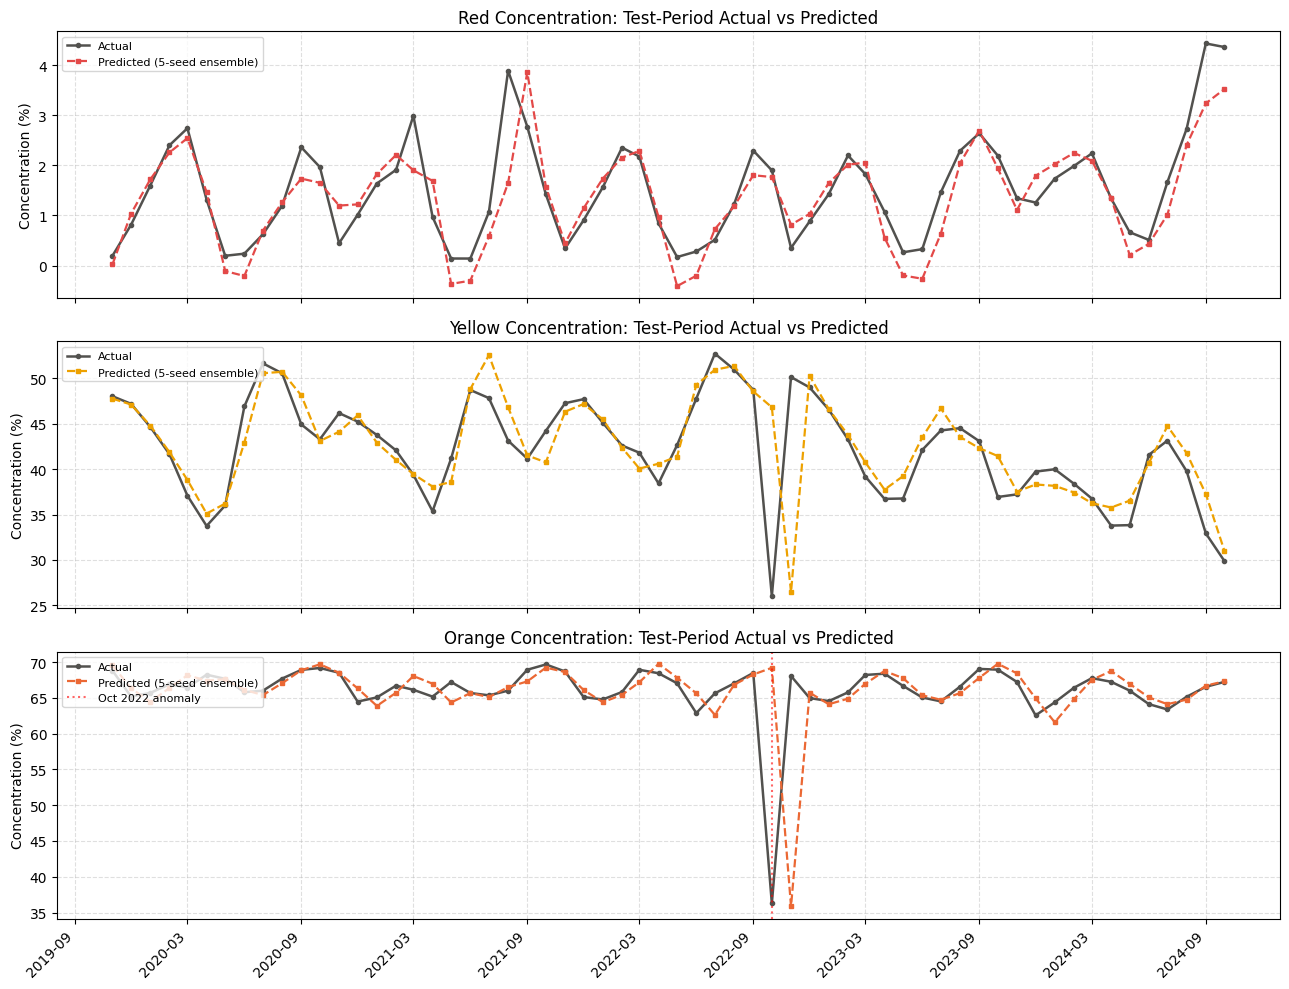

In [ ]:
# Cell 6 — Graph 1: Actual vs Predicted (test period, real dates)

fig, axes = plt.subplots(3,1, figsize=(13,10), sharex=True)
for ax, c in zip(axes, TARGET_NAMES):
    i = TARGET_NAMES.index(c)
    ax.plot(dates_test, y_test_real[:,i], label='Actual', color='#52514e', linewidth=1.8, marker='o', markersize=3)
    ax.plot(dates_test, mean_pred[:,i], label='Predicted (5-seed ensemble)', color=colors_plot[c], linewidth=1.6, linestyle='--', marker='s', markersize=3)
    if c == 'Orange':
        idx = dates_test[dates_test.dt.strftime('%Y-%m')=='2022-10'].index
        if len(idx): ax.axvline(dates_test[idx[0]], color='red', linestyle=':', alpha=0.6, label='Oct 2022 anomaly')
    ax.set_title(f'{c} Concentration: Test-Period Actual vs Predicted')
    ax.set_ylabel('Concentration (%)'); ax.legend(fontsize=8, loc='upper left')
    ax.grid(True, linestyle='--', alpha=0.4)
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.setp(axes[-1].get_xticklabels(), rotation=45, ha='right')
plt.tight_layout(); plt.savefig('phase4_g1_timeline.png', dpi=150); plt.show()

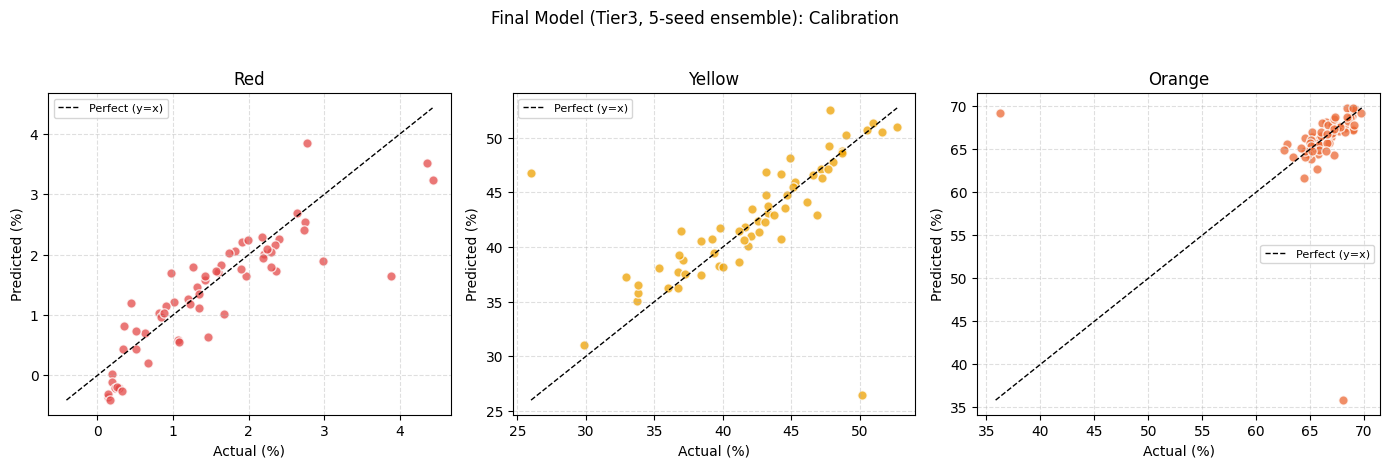

In [ ]:
# Cell 7 — Graph 2: Calibration scatter

fig, axes = plt.subplots(1,3, figsize=(14,4.5))
for ax, c in zip(axes, TARGET_NAMES):
    i = TARGET_NAMES.index(c)
    ax.scatter(y_test_real[:,i], mean_pred[:,i], color=colors_plot[c], alpha=0.75, edgecolor='white', s=45)
    lims = [min(y_test_real[:,i].min(), mean_pred[:,i].min()), max(y_test_real[:,i].max(), mean_pred[:,i].max())]
    ax.plot(lims, lims, 'k--', linewidth=1, label='Perfect (y=x)')
    ax.set_xlabel('Actual (%)'); ax.set_ylabel('Predicted (%)'); ax.set_title(c)
    ax.legend(fontsize=8); ax.grid(True, linestyle='--', alpha=0.4)
plt.suptitle('Final Model (Tier3, 5-seed ensemble): Calibration', y=1.03)
plt.tight_layout(); plt.savefig('phase4_g2_scatter.png', dpi=150); plt.show()

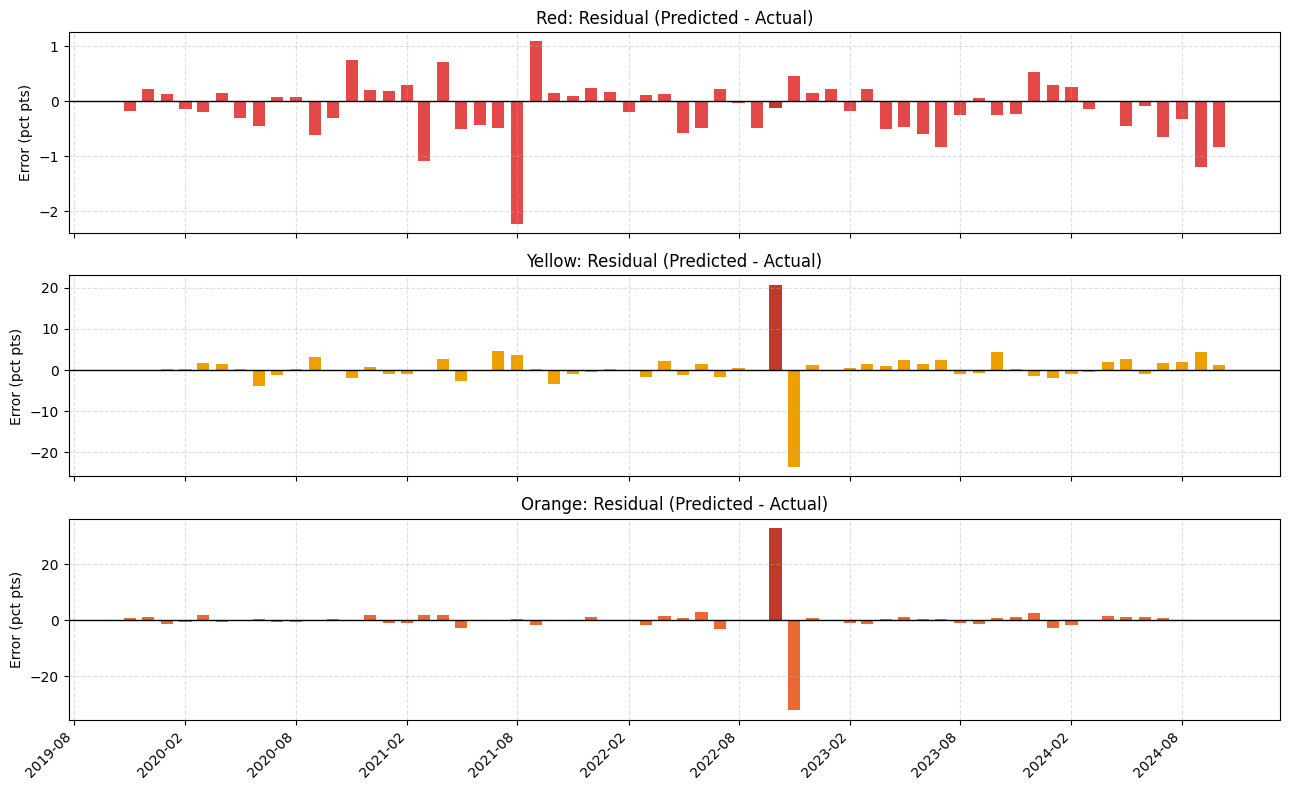

In [ ]:
# Cell 8 — Graph 3: Residuals over time

fig, axes = plt.subplots(3,1, figsize=(13,8), sharex=True)
for ax, c in zip(axes, TARGET_NAMES):
    i = TARGET_NAMES.index(c)
    residual = mean_pred[:,i] - y_test_real[:,i]
    bar_colors = ['#c0392b' if d.strftime('%Y-%m')=='2022-10' else colors_plot[c] for d in dates_test]
    ax.bar(dates_test, residual, width=20, color=bar_colors)
    ax.axhline(0, color='black', linewidth=1)
    ax.set_title(f'{c}: Residual (Predicted - Actual)'); ax.set_ylabel('Error (pct pts)')
    ax.grid(True, linestyle='--', alpha=0.4)
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.setp(axes[-1].get_xticklabels(), rotation=45, ha='right')
plt.tight_layout(); plt.savefig('phase4_g3_residuals.png', dpi=150); plt.show()

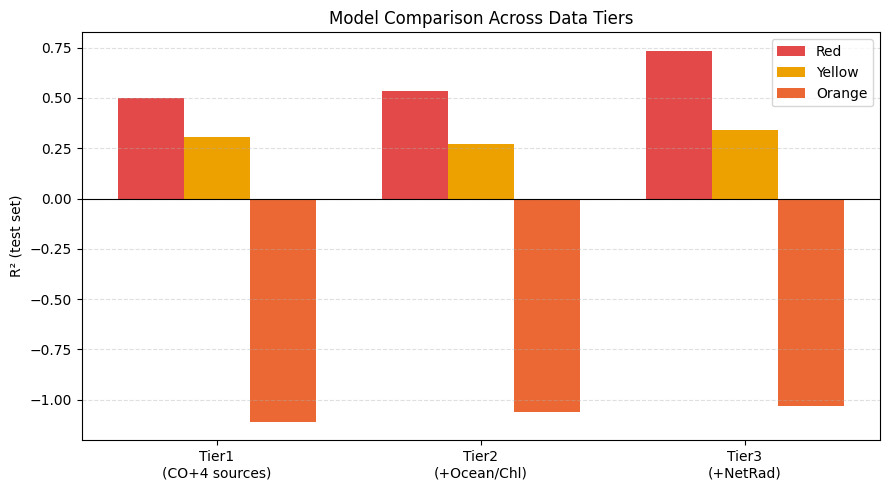

In [ ]:
# Cell 9 — Graph 4: Tier comparison (uses your saved Phase 3 results)

tc = pd.read_excel(DATA_DIR + 'CO_Phase3_Results.xlsx', sheet_name='Tier_Comparison')
pivot = tc.pivot(index='Tier', columns='Color', values='R2').reindex(['Tier1','Tier2','Tier3'])[TARGET_NAMES]

fig, ax = plt.subplots(figsize=(9,5))
x = np.arange(3); width = 0.25
for i,c in enumerate(TARGET_NAMES):
    ax.bar(x+i*width, pivot[c].values, width, label=c, color=colors_plot[c])
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x+width); ax.set_xticklabels(['Tier1\n(CO+4 sources)','Tier2\n(+Ocean/Chl)','Tier3\n(+NetRad)'])
ax.set_ylabel('R² (test set)'); ax.set_title('Model Comparison Across Data Tiers')
ax.legend(); ax.grid(True, axis='y', linestyle='--', alpha=0.4)
plt.tight_layout(); plt.savefig('phase4_g4_tiers.png', dpi=150); plt.show()

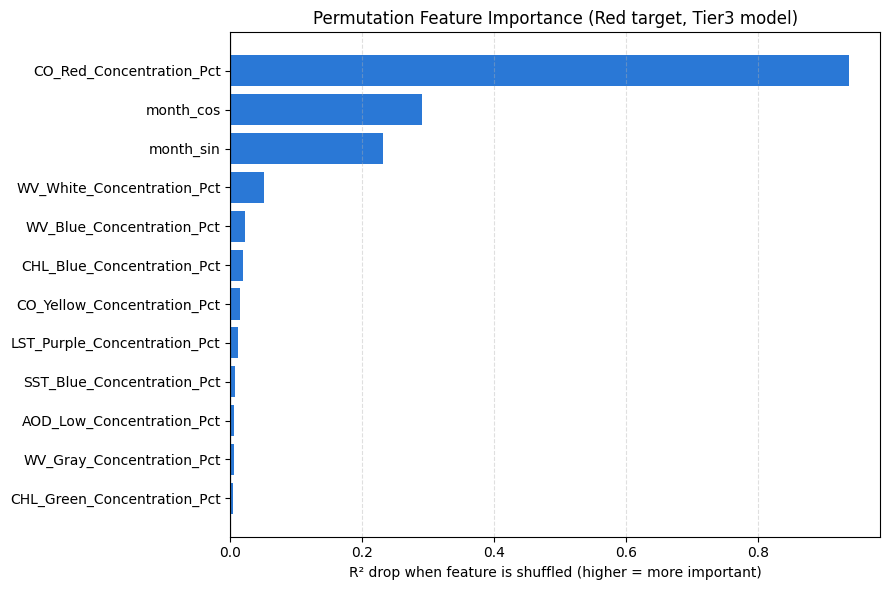

In [ ]:
# Cell 10 — Graph 5: Feature importance (uses your saved Phase 3 results)

fi = pd.read_excel(DATA_DIR + 'CO_Phase3_Results.xlsx', sheet_name='Feature_Importance')
fi = fi.sort_values('R2_Drop', ascending=True).tail(12)
fig, ax = plt.subplots(figsize=(9,6))
bar_colors = ['#2a78d6' if v>0 else '#b0b0b0' for v in fi['R2_Drop']]
ax.barh(fi['Feature'], fi['R2_Drop'], color=bar_colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('R² drop when feature is shuffled (higher = more important)')
ax.set_title('Permutation Feature Importance (Red target, Tier3 model)')
ax.grid(True, axis='x', linestyle='--', alpha=0.4)
plt.tight_layout(); plt.savefig('phase4_g5_importance.png', dpi=150); plt.show()

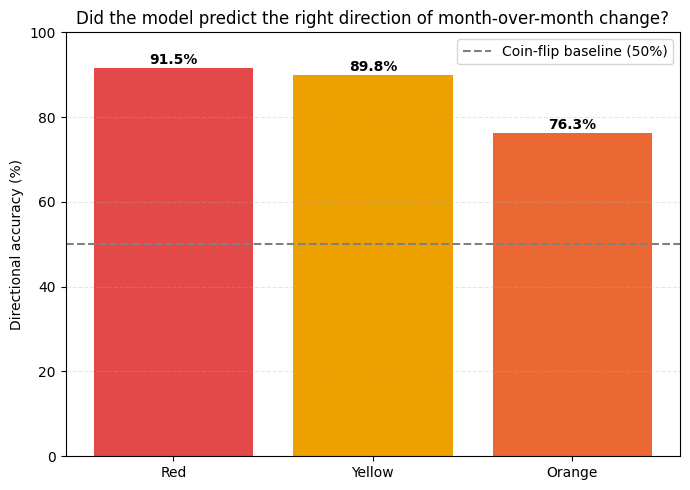

In [ ]:
# Cell 11 — Graph 6: Directional accuracy

fig, ax = plt.subplots(figsize=(7,5))
bars = ax.bar(dir_acc.keys(), dir_acc.values(), color=[colors_plot[c] for c in dir_acc])
ax.axhline(50, color='gray', linestyle='--', label='Coin-flip baseline (50%)')
for bar, v in zip(bars, dir_acc.values()):
    ax.text(bar.get_x()+bar.get_width()/2, v+1, f'{v:.1f}%', ha='center', fontweight='bold')
ax.set_ylabel('Directional accuracy (%)'); ax.set_ylim(0,100)
ax.set_title('Did the model predict the right direction of month-over-month change?')
ax.legend(); ax.grid(True, axis='y', linestyle='--', alpha=0.3)
plt.tight_layout(); plt.savefig('phase4_g6_directional.png', dpi=150); plt.show()

In [ ]:
# Cell 12 — Export everything to Excel for the presentation

output_path = DATA_DIR + 'CO_Phase4_Final_Results.xlsx'
with pd.ExcelWriter(output_path, engine='openpyxl') as writer:
    metrics_df.to_excel(writer, sheet_name='Final_Metrics', index=False)
    pd.DataFrame({'Date':dates_test, 'Actual_Red':y_test_real[:,0],'Pred_Red':mean_pred[:,0],
                  'Actual_Yellow':y_test_real[:,1],'Pred_Yellow':mean_pred[:,1],
                  'Actual_Orange':y_test_real[:,2],'Pred_Orange':mean_pred[:,2]}).to_excel(writer, sheet_name='Predictions', index=False)
    tc.to_excel(writer, sheet_name='Tier_Comparison', index=False)
    fi.to_excel(writer, sheet_name='Feature_Importance', index=False)

print(f"Saved: {output_path}")
from google.colab import files
files.download(output_path)
for f in ['phase4_g1_timeline.png','phase4_g2_scatter.png','phase4_g3_residuals.png',
          'phase4_g4_tiers.png','phase4_g5_importance.png','phase4_g6_directional.png']:
    files.download(f)

Saved: /content/drive/MyDrive/CS190-4P/multisource/CO_Phase4_Final_Results.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (5 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>